In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from scipy.stats import ttest_ind, f_oneway

In [2]:
iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)

df['species'] = iris.target
df['species_name'] = df['species'].map({
    0: 'setosa',
    1: 'versicolor',
    2: 'virginica'
})

df.head()
#The Iris dataset contains measurements of iris flowers from three species: setosa, versicolor, and virginica. 
#It includes four numerical features: sepal length, sepal width, petal length, and petal width.

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
df.shape
df.info()
df.describe()
df.isnull().sum()
#The dataset has 150 rows and 6 columns. There are 4 numerical feature columns, one encoded species column, and one species name column. 
#There are no missing values, so no imputation is required.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
 5   species_name       150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
species_name         0
dtype: int64

In [4]:
df.dtypes
numerical_cols = iris.feature_names
categorical_cols = ['species', 'species_name']

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)
#Sepal length, sepal width, petal length, and petal width are numerical continuous variables. 
#Species is a categorical variable because it represents flower classes.

Numerical columns: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Categorical columns: ['species', 'species_name']


In [5]:
summary_stats = df[numerical_cols].agg(['mean', 'var', 'std'])
summary_stats
#Mean shows the average value of each feature. Variance and standard deviation show how spread out the values are. 
#Petal length has higher variation compared to petal width, meaning petal length differs more across flower samples.

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
mean,5.843333,3.057333,3.758000,1.199333
var,0.685694,0.189979,3.116278,0.581006
std,0.828066,0.435866,1.765298,0.762238


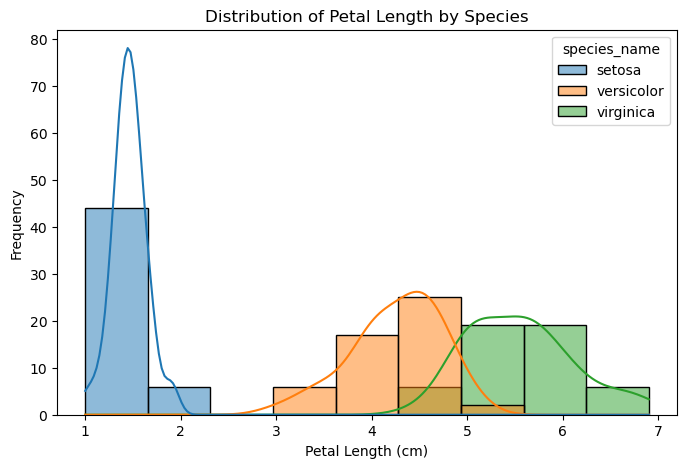

In [6]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='petal length (cm)', hue='species_name', kde=True)
plt.title('Distribution of Petal Length by Species')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Frequency')
plt.show()
#The histogram shows that setosa has much smaller petal length compared to versicolor and virginica. 
#This means petal length is useful for separating setosa from the other two species.

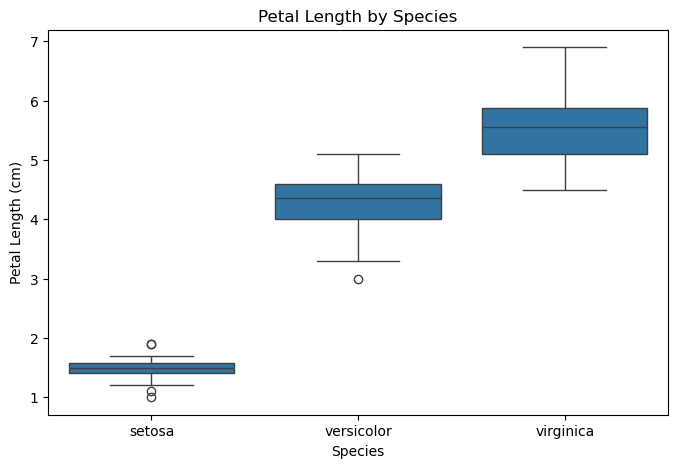

In [7]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='species_name', y='petal length (cm)')
plt.title('Petal Length by Species')
plt.xlabel('Species')
plt.ylabel('Petal Length (cm)')
plt.show()
#The boxplot shows clear differences in petal length among the three species. 
#Setosa has the smallest petal length, while virginica has the largest. 
#There is some overlap between versicolor and virginica, but setosa is clearly separated.

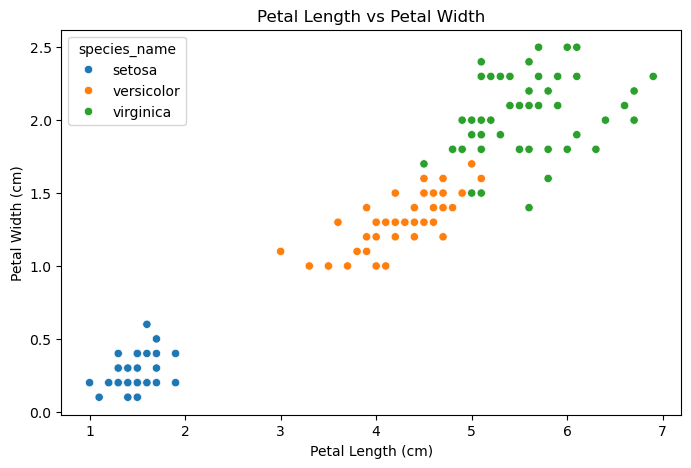

In [8]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x='petal length (cm)',
    y='petal width (cm)',
    hue='species_name'
)
plt.title('Petal Length vs Petal Width')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.show()
#The scatter plot shows a strong positive relationship between petal length and petal width. 
#As petal length increases, petal width also increases. 
#The species form visible clusters, especially setosa, which is clearly separated.

In [9]:
skewness = df[numerical_cols].skew().sort_values(ascending=False)
skewness

sepal width (cm)     0.318966
sepal length (cm)    0.314911
petal width (cm)    -0.102967
petal length (cm)   -0.274884
dtype: float64

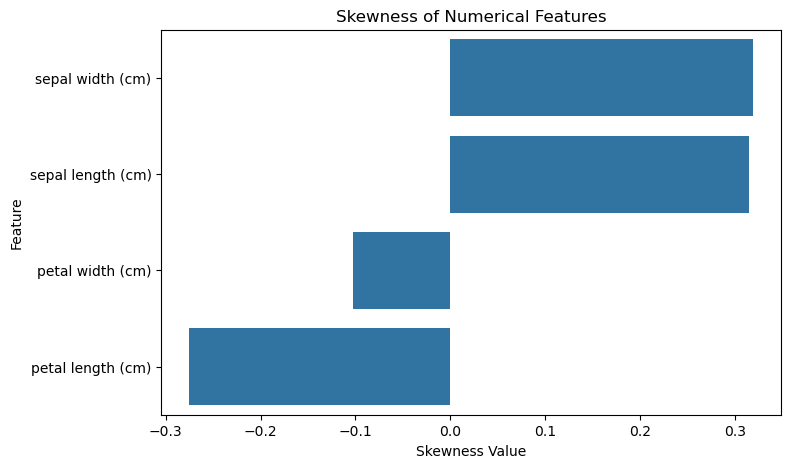

In [10]:
plt.figure(figsize=(8,5))
sns.barplot(x=skewness.values, y=skewness.index)
plt.title('Skewness of Numerical Features')
plt.xlabel('Skewness Value')
plt.ylabel('Feature')
plt.show()
#Skewness tells us whether a distribution is symmetric or stretched more to one side. 
#A positive skew means the distribution has a longer right tail, while a negative skew means it has a longer left tail. 
#In the Iris dataset, most features have only moderate skewness, so the distributions are not extremely skewed.

In [11]:
correlation = df[numerical_cols].corr()
correlation

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


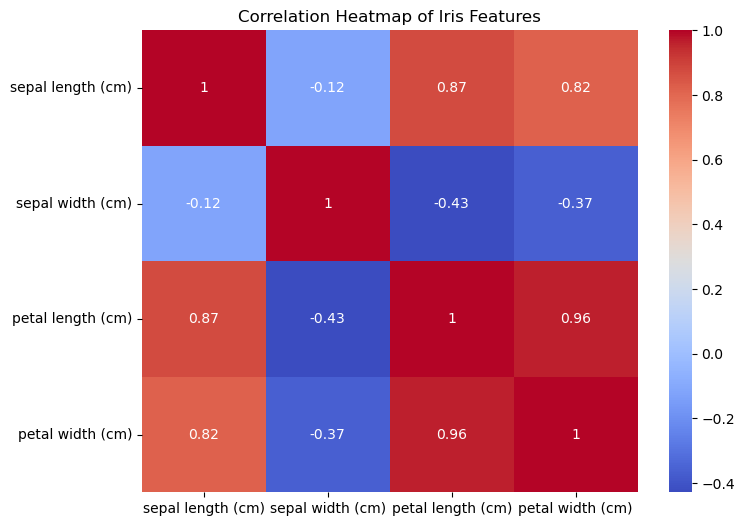

In [12]:
plt.figure(figsize=(8,6))
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap of Iris Features')
plt.show()

#Petal length and petal width have a strong positive correlation. 
#This means flowers with longer petals usually also have wider petals. 
#Sepal length also has a positive relationship with petal length and petal width, but sepal width shows weaker correlation.

In [13]:
setosa_petal_length = df[df['species_name'] == 'setosa']['petal length (cm)']
versicolor_petal_length = df[df['species_name'] == 'versicolor']['petal length (cm)']

t_stat, p_value = ttest_ind(setosa_petal_length, versicolor_petal_length)

print("T-statistic:", t_stat)
print("P-value:", p_value)

#The t-test compares the mean petal length of setosa and versicolor. 
#If the p-value is less than 0.05, we reject the null hypothesis and conclude that there is a statistically significant difference between the two groups.
#In this case, the p-value is very small, so petal length is significantly different between setosa and versicolor.

T-statistic: -39.492719391538095
P-value: 5.404910513441677e-62


In [14]:
setosa = df[df['species_name'] == 'setosa']['petal length (cm)']
versicolor = df[df['species_name'] == 'versicolor']['petal length (cm)']
virginica = df[df['species_name'] == 'virginica']['petal length (cm)']

f_stat, p_value = f_oneway(setosa, versicolor, virginica)

print("F-statistic:", f_stat)
print("P-value:", p_value)

#ANOVA compares the mean petal length across all three species. 
#If the p-value is less than 0.05, it means at least one species has a significantly different mean petal length.
#The p-value is very small, so there is a statistically significant difference in petal length among the three iris species.

F-statistic: 1180.1611822529785
P-value: 2.8567766109619814e-91
